In [16]:
import re
import pandas as pd
import numpy as np
from scipy import stats
from google.colab import files

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [19]:

uploaded = files.upload()

nama_file = list(uploaded.keys())[0]

print("File berhasil diunggah:", nama_file)


Saving Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx to Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx
File berhasil diunggah: Respons Gabungan 3 TI A - Versi Baru - 29 Butir.xlsx


In [20]:

# Membaca file Excel
JUMLAH_KOLOM_DEMOGRAFI = 2

df = pd.read_excel(nama_file)

# Memisahkan kolom pertanyaan
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

# Menampilkan informasi dataset
print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

# Menampilkan 5 baris pertama
df.head()


Jumlah responden : 38
Jumlah butir     : 29
Data kosong      : 0


,Cap waktu,Kelas,Penggunaan AI pada tugas atau projek kuliah [AI1. Saya menggunakan AI ketika mengerjakan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI2. Saya menggunakan AI untuk memahami persoalan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI3. Saya menggunakan AI untuk mencari ide pengerjaan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI4. Saya menggunakan AI untuk menyusun langkah penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI5. Saya menggunakan AI untuk memperoleh contoh penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI6. Saya menggunakan AI untuk mengembangkan jawaban tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI7. Saya menggunakan AI untuk meninjau jawaban tugas kuliah sebelum dikumpulkan.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS1. Saya merasa membutuhkan bantuan AI untuk mulai mengerjakan tugas kuliah.],...,Kebiasaan penggunaan teknologi digital [TD6. Saya menggunakan jawaban AI dalam tugas kuliah setelah membacanya sekilas.],Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah hingga mendekati batas pengumpulan.],Prokrastinasi akademik [PA2. Saya memulai pengerjaan tugas kuliah lebih lambat daripada waktu yang saya rencanakan.],Prokrastinasi akademik [PA3. Saya menunda melanjutkan tugas kuliah yang sudah saya mulai.],Prokrastinasi akademik [PA4. Saya menyelesaikan tugas kuliah pada saat waktu pengumpulan hampir berakhir.],Respons emosional [RE1. Saya merasa tertekan ketika waktu pengerjaan tugas menjadi singkat akibat menunda.],Respons emosional [RE2. Saya merasa cemas ketika tugas yang saya tunda mendekati batas pengumpulan.],Respons emosional [RE3. Saya merasa panik ketika beberapa tugas yang saya tunda harus segera dikumpulkan.],Respons emosional [RE4. Saya merasa gelisah ketika memikirkan tugas yang pengerjaannya saya tunda.],Respons emosional [RE5. Saya merasa kewalahan menghadapi tugas yang menumpuk akibat penundaan.]
0,2026-11-13 20:54:44.060,3 TI A,Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),...,Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Setuju (S)
1,2026-11-13 20:55:17.425,3 TI A,Sangat Tidak Setuju (STS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Sangat Setuju (SS),Setuju (S),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),...,Sangat Tidak Setuju (STS),Setuju (S),Setuju (S),Setuju (S),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Setuju (S)
2,2026-11-13 20:55:22.077,3 TI A,Sangat Tidak Setuju (STS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Tidak Setuju (TS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),...,Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS)
3,2026-11-13 20:55:28.868,3 TI A,Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Sangat Tidak Setuju (STS),...,Sangat Setuju (SS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Sangat Setuju (SS),Setuju (S),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Setuju (S)
4,2026-11-13 20:55:38.165,3 TI A,Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS),Setuju (S),Sangat Setuju (SS),Sangat Setuju (SS),...,Setuju (S),Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Sangat Setuju (SS),Setuju (S),Tidak Setuju (TS),Sangat Tidak Setuju (STS),Tidak Setuju (TS)


In [21]:

# Mengubah jawaban Likert menjadi angka
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

# Memeriksa apakah ada jawaban yang gagal dikonversi
print("Sel yang gagal dikonversi:",
      int(num.isna().sum().sum()))

# Menampilkan hasil konversi
num.head()


Sel yang gagal dikonversi: 0


/tmp/ipykernel_541/2200463354.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [AI1. Saya menggunakan AI ketika mengerjakan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI2. Saya menggunakan AI untuk memahami persoalan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI3. Saya menggunakan AI untuk mencari ide pengerjaan tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI4. Saya menggunakan AI untuk menyusun langkah penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI5. Saya menggunakan AI untuk memperoleh contoh penyelesaian tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI6. Saya menggunakan AI untuk mengembangkan jawaban tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [AI7. Saya menggunakan AI untuk meninjau jawaban tugas kuliah sebelum dikumpulkan.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS1. Saya merasa membutuhkan bantuan AI untuk mulai mengerjakan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS2. Saya merasa perlu memperoleh saran AI sebelum menentukan langkah pengerjaan tugas kuliah.],Aspek psikologis penggunaan AI pada tugas atau projek kuliah [PS3. Saya merasa lebih yakin terhadap jawaban tugas setelah memperoleh konfirmasi dari AI.],...,Kebiasaan penggunaan teknologi digital [TD6. Saya menggunakan jawaban AI dalam tugas kuliah setelah membacanya sekilas.],Prokrastinasi akademik [PA1. Saya menunda memulai tugas kuliah hingga mendekati batas pengumpulan.],Prokrastinasi akademik [PA2. Saya memulai pengerjaan tugas kuliah lebih lambat daripada waktu yang saya rencanakan.],Prokrastinasi akademik [PA3. Saya menunda melanjutkan tugas kuliah yang sudah saya mulai.],Prokrastinasi akademik [PA4. Saya menyelesaikan tugas kuliah pada saat waktu pengumpulan hampir berakhir.],Respons emosional [RE1. Saya merasa tertekan ketika waktu pengerjaan tugas menjadi singkat akibat menunda.],Respons emosional [RE2. Saya merasa cemas ketika tugas yang saya tunda mendekati batas pengumpulan.],Respons emosional [RE3. Saya merasa panik ketika beberapa tugas yang saya tunda harus segera dikumpulkan.],Respons emosional [RE4. Saya merasa gelisah ketika memikirkan tugas yang pengerjaannya saya tunda.],Respons emosional [RE5. Saya merasa kewalahan menghadapi tugas yang menumpuk akibat penundaan.]
0,1,2,4,5,4,2,1,1,2,4,...,2,1,2,4,5,1,2,4,5,4
1,1,2,1,5,5,4,1,1,2,1,...,1,4,4,4,1,5,1,1,5,4
2,1,2,1,2,2,2,1,2,2,1,...,2,1,2,2,1,1,2,2,1,2
3,5,4,2,1,2,4,5,1,2,4,...,5,1,2,5,4,1,2,4,5,4
4,5,4,2,1,2,4,5,5,4,2,...,4,5,4,2,1,5,4,2,1,2


In [22]:

# Mengelompokkan pertanyaan berdasarkan dimensi
dimensi = {}

for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1)
    dimensi.setdefault(nama, []).append(kolom)

# Menampilkan jumlah pertanyaan setiap dimensi
for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")


Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respons emosional: 5 butir


In [23]:

# Menghitung nilai r tabel
n = len(num)

t = stats.t.ppf(0.975, n - 2)

r_tabel = t / np.sqrt((n - 2) + t**2)

print("Jumlah responden:", n)
print("Derajat bebas (df):", n - 2)
print(f"Nilai r tabel (α=0,05): {r_tabel:.3f}")


Jumlah responden: 38
Derajat bebas (df): 36
Nilai r tabel (α=0,05): 0.320


In [24]:

# Uji Validitas menggunakan Korelasi Pearson

hasil_validitas = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)

    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)

        r_koreksi, _ = stats.pearsonr(
            x[kolom], total - x[kolom]
        )

        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid"
        })

# Membuat tabel hasil pengujian
tabel_validitas = pd.DataFrame(hasil_validitas)

display(tabel_validitas)


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.663,0.419,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.493,0.321,0.0017,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.678,0.513,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.212,-0.059,0.2020,Tidak valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.534,0.299,0.0006,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.475,0.271,0.0026,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.777,0.615,0.0000,Valid
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.495,0.134,0.0016,Valid
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.535,0.274,0.0005,Valid
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.565,0.324,0.0002,Valid


In [26]:

# Fungsi menghitung Cronbach's Alpha
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (
        1 - x.var(ddof=1).sum() /
        x.sum(axis=1).var(ddof=1)
    )

# Fungsi menentukan kategori reliabilitas
def kategori(a):
    return (
        "Sangat baik" if a >= 0.90
        else "Baik" if a >= 0.80
        else "Reliabel" if a >= 0.70
        else "Tidak reliabel"
    )

# Menyiapkan hasil pengujian
hasil_reliabilitas = []
alpha_dihapus = []

# Menguji setiap dimensi
for nama, daftar in dimensi.items():
    x = num[daftar]

    a = cronbach_alpha(x)

    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's Alpha": round(a, 3),
        "Kategori": kategori(a)
    })

    # Menghitung Alpha jika setiap butir dihapus
    if len(daftar) > 2:
        for i, kolom in enumerate(daftar, 1):
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(
                    cronbach_alpha(x.drop(columns=kolom)), 3
                )
            })

# Membuat tabel hasil
tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

display(tabel_reliabilitas)
display(tabel_alpha_dihapus)


,Dimensi,Jumlah butir,Cronbach's Alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.612,Tidak reliabel
1,Aspek psikologis penggunaan AI pada tugas atau...,7,0.371,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.230,Tidak reliabel
3,Prokrastinasi akademik,4,0.012,Tidak reliabel
4,Respons emosional,5,0.501,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.539
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.580
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.516
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.696
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.585
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.592
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.460
7,Aspek psikologis penggunaan AI pada tugas atau...,B1,0.358
8,Aspek psikologis penggunaan AI pada tugas atau...,B2,0.275
9,Aspek psikologis penggunaan AI pada tugas atau...,B3,0.250


In [27]:

# Analisis deskriptif setiap dimensi

for nama, daftar in dimensi.items():
    x = num[daftar]

    skor_total = x.sum(axis=1)

    print("\nDimensi:", nama)
    print("Rata-rata       :", round(skor_total.mean(), 3))
    print("Standar deviasi :", round(skor_total.std(), 3))
    print("Skewness        :", round(skor_total.skew(), 3))
    print("Kurtosis        :", round(skor_total.kurt(), 3))



Dimensi: Penggunaan AI pada tugas atau projek kuliah
Rata-rata       : 22.947
Standar deviasi : 5.955
Skewness        : 0.203
Kurtosis        : -0.429

Dimensi: Aspek psikologis penggunaan AI pada tugas atau projek kuliah
Rata-rata       : 22.105
Standar deviasi : 4.831
Skewness        : 0.366
Kurtosis        : -0.076

Dimensi: Kebiasaan penggunaan teknologi digital
Rata-rata       : 17.947
Standar deviasi : 4.165
Skewness        : -0.041
Kurtosis        : 1.332

Dimensi: Prokrastinasi akademik
Rata-rata       : 11.316
Standar deviasi : 3.137
Skewness        : -0.17
Kurtosis        : 0.508

Dimensi: Respons emosional
Rata-rata       : 17.079
Standar deviasi : 4.395
Skewness        : 0.073
Kurtosis        : -0.923


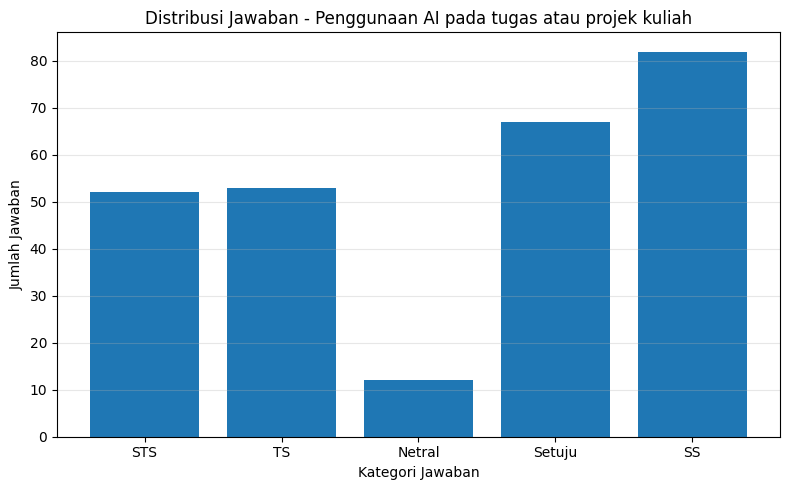

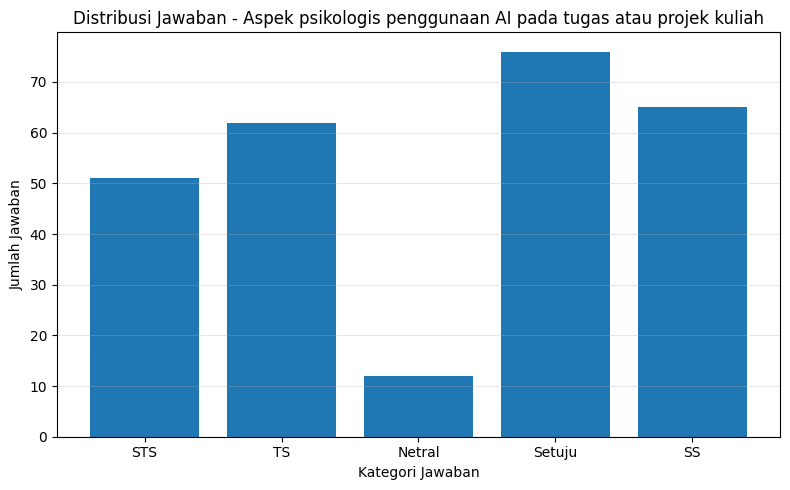

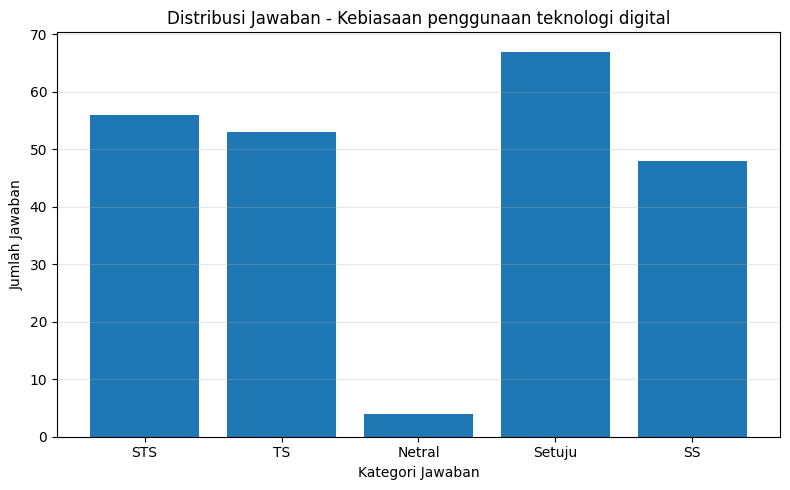

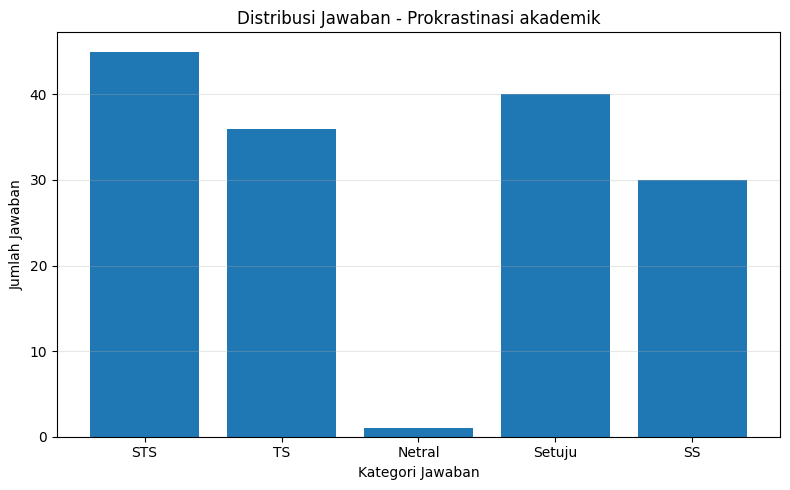

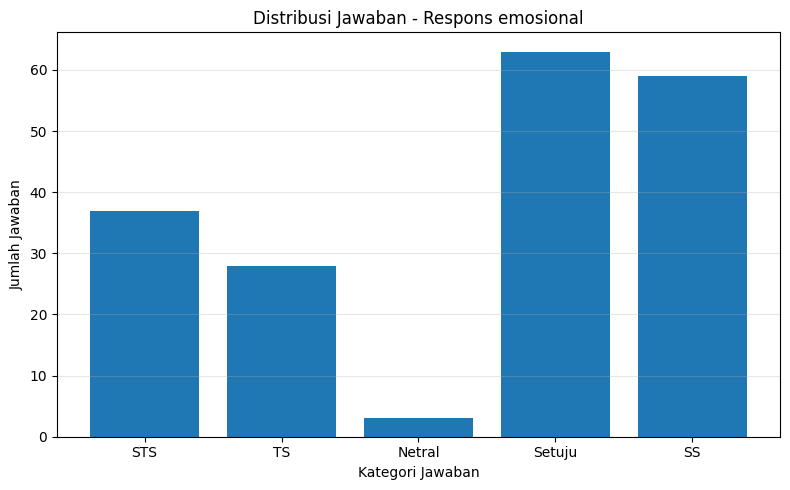

In [28]:

import matplotlib.pyplot as plt

label_jawaban = {
    1: "STS",
    2: "TS",
    3: "Netral",
    4: "Setuju",
    5: "SS"
}

for nama, daftar in dimensi.items():
    data_dimensi = num[daftar].stack()

    frekuensi = (
        data_dimensi.value_counts()
        .reindex([1, 2, 3, 4, 5], fill_value=0)
    )

    plt.figure(figsize=(8, 5))
    plt.bar(
        [label_jawaban[i] for i in frekuensi.index],
        frekuensi.values
    )

    plt.title(f"Distribusi Jawaban - {nama}")
    plt.xlabel("Kategori Jawaban")
    plt.ylabel("Jumlah Jawaban")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [30]:

# Mengekspor hasil pengujian ke Excel

nama_output = "Hasil_Uji_Validitas_Reliabilitas.xlsx"

with pd.ExcelWriter(nama_output) as writer:
    tabel_validitas.to_excel(
        writer, sheet_name="Uji Validitas", index=False
    )
    tabel_reliabilitas.to_excel(
        writer, sheet_name="Uji Reliabilitas", index=False
    )
    tabel_alpha_dihapus.to_excel(
        writer, sheet_name="Alpha Jika Dihapus", index=False
    )

    num.to_excel(
        writer, sheet_name="Data Numerik", index=False
    )

files.download(nama_output)

print("File hasil pengujian berhasil dibuat!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File hasil pengujian berhasil dibuat!
